**04_evaluation.ipynb**

Purpose:
- Evaluate trained vehicle classification model
- Analyze per-class performance
- Generate confusion matrix & metrics
- Identify weaknesses before deployment



In [13]:
import json
import numpy as np
import tensorflow as tf
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.metrics import (
    confusion_matrix,
    classification_report,
)

from google.colab import drive
drive.mount('/content/drive')

import os
os.chdir("/content/drive/MyDrive/Vehicle-type-classification")

from src.data_loader import create_generators

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [14]:
with open("artifacts/config.json", "r") as f:
  config = json.load(f)

with open("artifacts/class_indices.json", "r") as f:
  class_indices = json.load(f)

idx_to_class = {v: k for k, v in class_indices.items()}
NUM_CLASSES = len(class_indices)
print("class mapping: ", idx_to_class)

class mapping:  {0: 'Bus', 1: 'Car', 2: 'Three Wheeler', 3: 'Truck', 4: 'motorcycle'}


In [15]:
_, val_generator = create_generators(config)

Found 3463 images belonging to 5 classes.
Found 863 images belonging to 5 classes.


In [16]:
model = tf.keras.models.load_model("models/vehicle_classifier_best.keras", compile=False)
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ mobilenetv2_1.00_224            │ (None, 7, 7, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 1280)           │         5,120 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       163,968 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 5)              │           645 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,427,717 (9.26 MB)

 Trainable params: 1,693,573 (6.46 MB)

 Non-trainable params: 734,144 (2.80 MB)

In [17]:
y_true = val_generator.classes
val_generator.reset()
y_pred_probs = model.predict(val_generator)
y_pred = np.argmax(y_pred_probs, axis=1)

27/27 ━━━━━━━━━━━━━━━━━━━━ 396s 15s/step


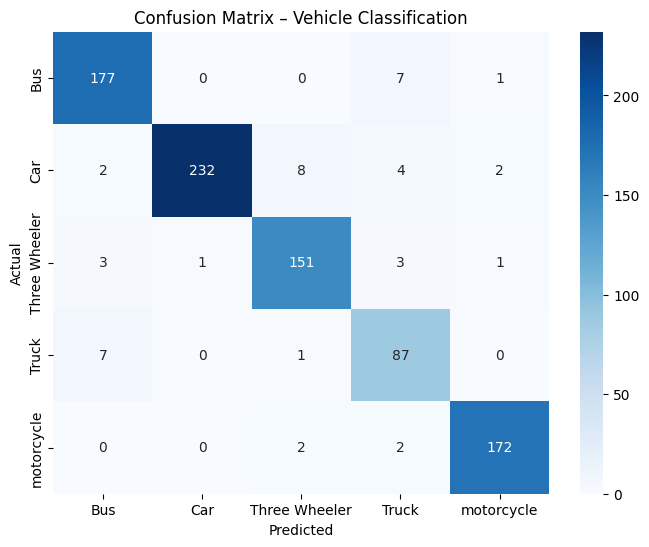

In [18]:
cm = confusion_matrix(y_true, y_pred)

plt.figure(figsize=(8,6))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=idx_to_class.values(),
    yticklabels=idx_to_class.values()
)

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix – Vehicle Classification")
plt.show()

In [19]:
report = classification_report(
    y_true,
    y_pred,
    target_names=idx_to_class.values(),
    output_dict=True
)

print(classification_report(
    y_true,
    y_pred,
    target_names=idx_to_class.values()
))

               precision    recall  f1-score   support

          Bus       0.94      0.96      0.95       185
          Car       1.00      0.94      0.96       248
Three Wheeler       0.93      0.95      0.94       159
        Truck       0.84      0.92      0.88        95
   motorcycle       0.98      0.98      0.98       176

     accuracy                           0.95       863
    macro avg       0.94      0.95      0.94       863
 weighted avg       0.95      0.95      0.95       863



In [ ]:
import json
import numpy as np
import tensorflow as tf
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.metrics import (
    confusion_matrix,
    classification_report,
)

from google.colab import drive
drive.mount('/content/drive')

import os
os.chdir("/content/drive/MyDrive/Vehicle-type-classification")

from src.data_loader import create_generators

with open("artifacts/config.json", "r") as f:
  config = json.load(f)

with open("artifacts/class_indices.json", "r") as f:
  class_indices = json.load(f)

idx_to_class = {v: k for k, v in class_indices.items()}
NUM_CLASSES = len(class_indices)
print("class mapping: ", idx_to_class)

_, val_generator = create_generators(config)

model = tf.keras.models.load_model("models/vehicle_mobilenetv2_stage2.keras")
model.summary()

y_true = val_generator.classes
val_generator.reset()
y_pred_probs = model.predict(val_generator)
y_pred = np.argmax(y_pred_probs, axis=1)

cm = confusion_matrix(y_true, y_pred)

plt.figure(figsize=(8,6))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=idx_to_class.values(),
    yticklabels=idx_to_class.values()
)

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix – Vehicle Classification")
plt.show()